In [15]:
## IMPORTS AND DATASET LOADING
import numpy as np
import pandas as pd
import os

path = r'C:\Users\Pratham Shah\Downloads'
os.chdir(path)

df = pd.read_csv('microbial_multi_env_data.csv')


import xgboost as xgb
from xgboost import XGBRegressor
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.metrics import mean_squared_error, r2_score

print(df.head())

  species_id broth_id  gene_1  gene_2  gene_3  gene_4  gene_5  gene_6  gene_7  \
0  Species_1  Broth_1       0       1       0       0       0       1       0   
1  Species_1  Broth_2       0       1       0       0       0       1       0   
2  Species_1  Broth_3       0       1       0       0       0       1       0   
3  Species_1  Broth_4       0       1       0       0       0       1       0   
4  Species_1  Broth_5       0       1       0       0       0       1       0   

   gene_8  gene_9  gene_10  iron_concentration carbon_source  \
0       0       0        1            3.015044       acetate   
1       0       0        1            3.912468      fructose   
2       0       0        1            8.526253       acetate   
3       0       0        1            3.237528      fructose   
4       0       0        1            1.777978       acetate   

   suppression_score  
0           0.143090  
1           0.345445  
2           0.307703  
3           0.144910  
4           0

In [16]:
# 1. Keep the labels in a separate variable for later use in GNN
metadata = df[['species_id', 'broth_id']].copy()

# 2. Separate features (X) and target (y)
# We drop the IDs because the genes and nutrients already describe the "Identity" and "Context"
X = df.drop(['suppression_score', 'species_id', 'broth_id'], axis=1).copy()
y = df['suppression_score'].copy()

# 3. One-hot encode only the nutrients (Carbon Source)
X = pd.get_dummies(X, columns=['carbon_source'], dtype=int)

# Verify the transformation
print(X.head())

   gene_1  gene_2  gene_3  gene_4  gene_5  gene_6  gene_7  gene_8  gene_9  \
0       0       1       0       0       0       1       0       0       0   
1       0       1       0       0       0       1       0       0       0   
2       0       1       0       0       0       1       0       0       0   
3       0       1       0       0       0       1       0       0       0   
4       0       1       0       0       0       1       0       0       0   

   gene_10  iron_concentration  carbon_source_acetate  carbon_source_fructose  \
0        1            3.015044                      1                       0   
1        1            3.912468                      0                       1   
2        1            8.526253                      1                       0   
3        1            3.237528                      0                       1   
4        1            1.777978                      1                       0   

   carbon_source_glucose  
0                      

In [17]:
# Split the data
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [18]:
## HYPERPARAMETER TUNING
param_grid = {
    'max_depth': [3, 4, 5],
    'learning_rate': [0.1, 0.01, 0.001],
    'gamma': [0, 0.25],
    'reg_lambda': [1, 5]
}

grid_search = GridSearchCV(
    estimator=XGBRegressor(objective='reg:squarederror', seed=42),
    param_grid=param_grid,
    scoring='neg_mean_squared_error',
    cv=3,
    n_jobs=-1,
    verbose=2
)

grid_search.fit(X_train, y_train)
print("Best Parameters:", grid_search.best_params_)

param_grid2 = {
    'max_depth': [2,3,4],
    'learning_rate': [0.05,0.1,0.2,0.3],
    'gamma': [0],
    'reg_lambda': [1, 5]
}

grid_search2 = GridSearchCV(
    estimator=XGBRegressor(objective='reg:squarederror', seed=42),
    param_grid=param_grid2,
    scoring='neg_mean_squared_error',
    cv=3,
    n_jobs=-1,
    verbose=2
)

grid_search2.fit(X_train, y_train)
print("Best Parameters:", grid_search2.best_params_)

param_grid3 = {
    'max_depth': [2,3, 4, 5],
    'learning_rate': [0.05,0.1,0.2,0.25,0.3],
    'gamma': [0, 0.25],
    'reg_lambda': [1, 5]
}

grid_search3 = GridSearchCV(
    estimator=XGBRegressor(objective='reg:squarederror', seed=42),
    param_grid=param_grid3,
    scoring='neg_mean_squared_error',
    cv=3,
    n_jobs=-1,
    verbose=2
)

grid_search3.fit(X_train, y_train)
print("Best Parameters:", grid_search3.best_params_)


Fitting 3 folds for each of 36 candidates, totalling 108 fits
Best Parameters: {'gamma': 0, 'learning_rate': 0.1, 'max_depth': 3, 'reg_lambda': 1}
Fitting 3 folds for each of 24 candidates, totalling 72 fits
Best Parameters: {'gamma': 0, 'learning_rate': 0.3, 'max_depth': 2, 'reg_lambda': 5}
Fitting 3 folds for each of 80 candidates, totalling 240 fits
Best Parameters: {'gamma': 0, 'learning_rate': 0.25, 'max_depth': 2, 'reg_lambda': 5}


In [13]:
# FINAL MODEL

reg_xgb_final = xgb.XGBRegressor(
    objective='reg:squarederror',
    seed=42,
    **grid_search3.best_params_,
    early_stopping_rounds=10,
    eval_metric='rmse'
)

reg_xgb_final.fit(
    X_train, y_train,
    eval_set=[(X_test, y_test)],
    verbose=True
)

# Print the best tree number (iteration)
print(f"Best Iteration: {reg_xgb_final.best_iteration}")

# Print the best score achieved
print(f"Best Score: {reg_xgb_final.best_score}")


[0]	validation_0-rmse:0.15602
[1]	validation_0-rmse:0.13623
[2]	validation_0-rmse:0.12317
[3]	validation_0-rmse:0.11288
[4]	validation_0-rmse:0.10426
[5]	validation_0-rmse:0.09751
[6]	validation_0-rmse:0.08993
[7]	validation_0-rmse:0.08447
[8]	validation_0-rmse:0.07960
[9]	validation_0-rmse:0.07616
[10]	validation_0-rmse:0.07275
[11]	validation_0-rmse:0.06967
[12]	validation_0-rmse:0.06738
[13]	validation_0-rmse:0.06561
[14]	validation_0-rmse:0.06425
[15]	validation_0-rmse:0.06380
[16]	validation_0-rmse:0.06273
[17]	validation_0-rmse:0.06212
[18]	validation_0-rmse:0.06116
[19]	validation_0-rmse:0.06085
[20]	validation_0-rmse:0.06041
[21]	validation_0-rmse:0.06071
[22]	validation_0-rmse:0.06034
[23]	validation_0-rmse:0.06023
[24]	validation_0-rmse:0.05978
[25]	validation_0-rmse:0.05867
[26]	validation_0-rmse:0.05887
[27]	validation_0-rmse:0.05811
[28]	validation_0-rmse:0.05805
[29]	validation_0-rmse:0.05771
[30]	validation_0-rmse:0.05764
[31]	validation_0-rmse:0.05784
[32]	validation_0-

R2 Score: 0.8910
Mean Absolute Error: 0.0454
     gene_1  gene_2  gene_3  gene_4  gene_5  gene_6  gene_7  gene_8  gene_9  \
361       1       0       0       1       0       0       1       1       0   
73        1       1       0       1       0       1       1       1       0   
374       1       1       1       1       0       1       1       0       1   
155       0       0       0       0       0       1       0       1       0   
104       0       1       1       1       1       1       1       1       1   
..      ...     ...     ...     ...     ...     ...     ...     ...     ...   
347       0       1       0       1       0       0       0       1       1   
86        0       1       0       1       0       0       1       0       1   
75        1       1       0       1       0       1       1       1       0   
438       0       1       0       1       1       1       1       1       0   
15        0       0       0       0       1       0       1       1       1   

     g

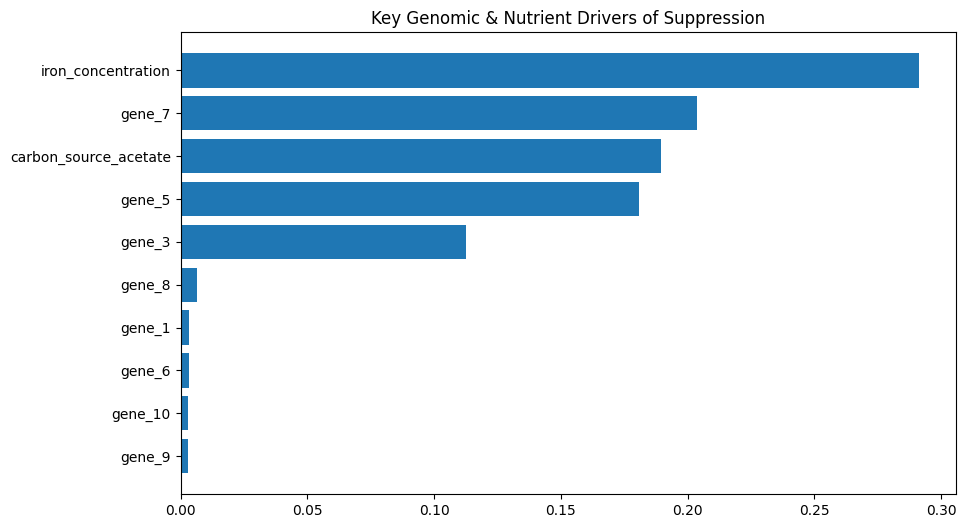

In [14]:
predictions = reg_xgb_final.predict(X_test)
print(f"R2 Score: {r2_score(y_test, predictions):.4f}") 
print(f"Mean Absolute Error: {np.mean(np.abs(y_test - predictions)):.4f}")
print(X_test)
print(y_test)
print(predictions)


importances = reg_xgb_final.feature_importances_
feat_df = pd.DataFrame({'Feature': X.columns, 'Importance': importances}).sort_values(by='Importance', ascending=False)

plt.figure(figsize=(10, 6))
plt.barh(feat_df['Feature'][:10], feat_df['Importance'][:10])
plt.title("Key Genomic & Nutrient Drivers of Suppression")
plt.gca().invert_yaxis()
plt.show()